# Лабораторная работа 2 по разработке сверточной нейронной сети с использованием PyTorch
<h2> Выполнил Прокофьев Кирилл 3825М1ФИ1</h2>

## Import and configuration

In [4]:
import os, random, time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as T
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

device = 'cuda' if torch.cuda.is_available() else 'cpu'
BATCH_SIZE, EPOCHS, LR, WEIGHT_DECAY = 128, 40, 0.05, 5e-4
NUM_WORKERS = 0 if os.name == 'nt' else 4

print(torch.__version__, device)

2.9.0+cu128 cuda


## Data loading and preprocessing

In [5]:
# Channel-wise mean/std normalization for CIFAR-10

MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                      T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

train_set = torchvision.datasets.CIFAR10('./data', train=True, download=True, transform=train_tf)
train_eval_set = torchvision.datasets.CIFAR10('./data', train=True, download=True, transform=eval_tf)
test_set = torchvision.datasets.CIFAR10('./data', train=False, download=True, transform=eval_tf)

train_loader = DataLoader(train_set, BATCH_SIZE, shuffle=True, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
train_eval_loader = DataLoader(train_eval_set, 512, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_set, 512, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)
classes = train_set.classes

100.0%


## Data dimensions

In [6]:
img, lbl = train_set[0]
print(f'train: {len(train_set)} samples, test: {len(test_set)} samples')
print(f'image: {tuple(img.shape)} (C,H,W), dtype={img.dtype}')
print(f'label: scalar int, meaning={lbl} ({classes[lbl]}), total number of classes={len(classes)}')

xb, yb = next(iter(train_loader))
print(f'batch of images: {tuple(xb.shape)}, batch of labels: {tuple(yb.shape)}')
print('classes:', classes)

train: 50000 samples, test: 10000 samples
image: (3, 32, 32) (C,H,W), dtype=torch.float32
label: scalar int, meaning=6 (frog), total number of classes=10
batch of images: (128, 3, 32, 32), batch of labels: (128,)
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Visualization

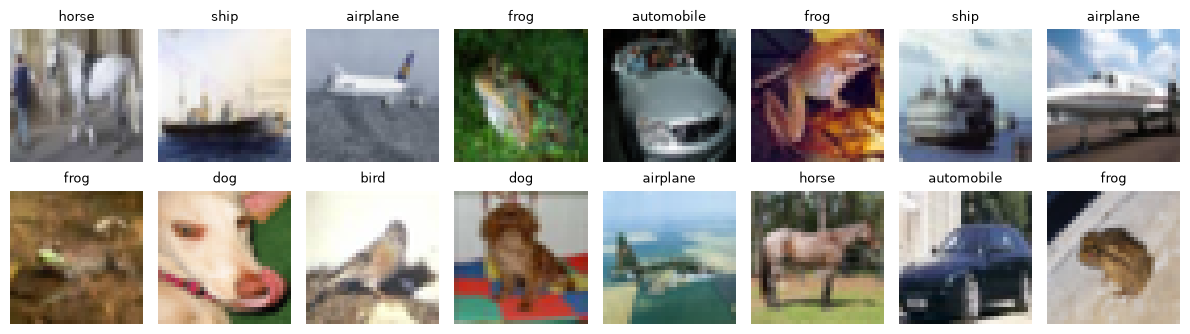

In [7]:
mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)
idx = np.random.choice(len(train_eval_set), 16, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.flat, idx):
    img, lbl = train_eval_set[i]
    ax.imshow((img * std + mean).permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(classes[lbl], fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## Architecture: VGG-11 (configuration A) + BatchNorm

In [8]:
CFG = {
    'VGG11': [64, 'M', 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M']
}

class VGG(nn.Module):
    def __init__(self, cfg, num_classes=10, hidden=4096, p=0.5):
        super().__init__()
        layers, c_in = [], 3
        for v in cfg:
            if v == 'M':
                layers += [nn.MaxPool2d(2, 2)]
            else:
                layers += [nn.Conv2d(c_in, v, 3, padding=1, bias=False),
                           nn.BatchNorm2d(v), nn.ReLU(inplace=True)]
                c_in = v
        self.features = nn.Sequential(*layers)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c_in, hidden), nn.ReLU(inplace=True), nn.Dropout(p),
            nn.Linear(hidden, hidden), nn.ReLU(inplace=True), nn.Dropout(p),
            nn.Linear(hidden, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01); nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.avgpool(self.features(x))
        return self.classifier(x)


model = VGG(CFG['VGG11']).to(device)
print(model)
print('learnable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
   

## Training 

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=[int(0.5 * EPOCHS), int(0.75 * EPOCHS)], gamma=0.1)
scaler = torch.amp.GradScaler('cuda', enabled=device == 'cuda')


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.amp.autocast('cuda', enabled=device == 'cuda'):
            out = model(x)
            loss = criterion(out, y)
        loss_sum += loss.item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += y.size(0)
    return loss_sum / n, correct / n


history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0 = time.time()
    for x, y in train_loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=device == 'cuda'):
            out = model(x)
            loss = criterion(out, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
    scheduler.step()

    tr_loss, tr_acc = evaluate(model, train_eval_loader)
    te_loss, te_acc = evaluate(model, test_loader)
    history['train_loss'].append(tr_loss); history['train_acc'].append(tr_acc)
    history['test_loss'].append(te_loss);  history['test_acc'].append(te_acc)

    print(f'epoch {epoch:02d}/{EPOCHS} | '
          f'train loss {tr_loss:.4f}, acc {tr_acc*100:5.2f}% | '
          f'test loss {te_loss:.4f}, acc {te_acc*100:5.2f}% | '
          f'lr {scheduler.get_last_lr()[0]:.4f} | {time.time()-t0:.1f} s')

epoch 01/40 | train loss 1.2050, acc 56.85% | test loss 1.2077, acc 56.36% | lr 0.0500 | 65.2 s
epoch 02/40 | train loss 1.1390, acc 60.68% | test loss 1.1815, acc 59.63% | lr 0.0500 | 46.1 s
epoch 03/40 | train loss 0.7942, acc 72.47% | test loss 0.8397, acc 71.07% | lr 0.0500 | 46.3 s
epoch 04/40 | train loss 0.8563, acc 71.72% | test loss 0.8899, acc 70.53% | lr 0.0500 | 46.1 s
epoch 05/40 | train loss 0.7138, acc 75.90% | test loss 0.7730, acc 74.17% | lr 0.0500 | 46.2 s
epoch 06/40 | train loss 0.6524, acc 77.99% | test loss 0.7217, acc 76.32% | lr 0.0500 | 45.1 s
epoch 07/40 | train loss 0.5783, acc 80.38% | test loss 0.6534, acc 78.11% | lr 0.0500 | 44.6 s
epoch 08/40 | train loss 0.6062, acc 79.95% | test loss 0.7164, acc 77.16% | lr 0.0500 | 44.0 s
epoch 09/40 | train loss 0.5093, acc 82.82% | test loss 0.6246, acc 79.66% | lr 0.0500 | 43.7 s
epoch 10/40 | train loss 0.5366, acc 81.81% | test loss 0.6329, acc 79.05% | lr 0.0500 | 43.4 s
epoch 11/40 | train loss 0.5100, acc 82.

## Test result

In [10]:
test_loss, test_acc = evaluate(model, test_loader)
train_loss, train_acc = evaluate(model, train_eval_loader)
print(f'TRAIN: loss {train_loss:.4f}, error {100*(1-train_acc):.2f}%,  accuracy {100*train_acc:.2f}%')
print(f'TEST : loss {test_loss:.4f}, error {100*(1-test_acc):.2f}%, accuracy {100*test_acc:.2f}%')

TRAIN: loss 0.0548, error 1.74%,  accuracy 98.26%
TEST : loss 0.3275, error 9.49%, accuracy 90.51%


## Error plot

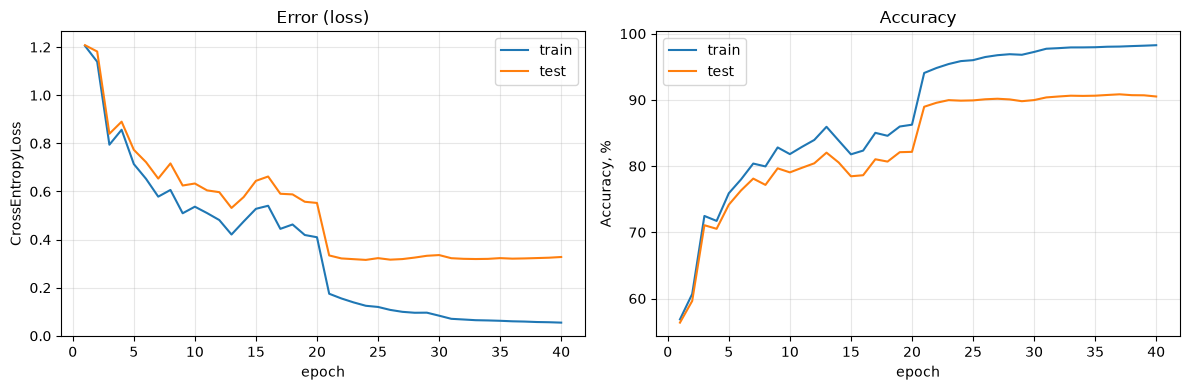

In [11]:
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, history['train_loss'], label='train')
ax[0].plot(ep, history['test_loss'], label='test')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('CrossEntropyLoss')
ax[0].set_title('Error (loss)'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ep, np.array(history['train_acc']) * 100, label='train')
ax[1].plot(ep, np.array(history['test_acc']) * 100, label='test')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('Accuracy, %')
ax[1].set_title('Accuracy'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()